# P5 프로젝트 — 서울 따릉이 대여소의 이용 패턴 발견

**K-means 군집화 | 3주 실습**

> **프로젝트 질문:** 따릉이 대여소의 평일·주말 이용 시간은 서로 어떻게 다를까? 비슷한 대여소를 묶으면 운영에 도움이 될까?

P1에서는 자전거 **대여량을 예측**했습니다. 이번에는 정답이 없는 상태에서 대여소의 **이용 유형을 발견**합니다.

| 주차 | 이번 주에 할 일 |
|---|---|
| **1주차 · 살펴보기** | 데이터를 이해하고 평일·주말 이용 패턴 탐색 |
| **2주차 · 군집화하기** | K-means 실행, 군집 수 선택, 이용량과 이용 패턴 비교 |
| **3주차 · 판단하기** | 군집 특성·계절성 해석, 운영 방안과 한계 제안 |

**진행 방법:** 코드를 위에서부터 실행하고, `TODO`로 표시된 설정을 바꿔 실험합니다. 중간의 **✍️ 기록**은 본인의 관찰과 판단으로 작성하세요. AI의 도움을 받아도 좋지만 설명은 스스로 할 수 있어야 합니다.

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"  # Windows에서 K-means 메모리 누수 방지

## 1주차. 데이터는 무엇을 말해 줄까?

### 1. 데이터 불러오기

교수자가 준비한 CSV 한 개로 실습합니다. **한 행은 대여소 한 곳**, 열에는 2025년 월별 대여건수와 평일·주말 시간대별 일평균 대여건수가 담겨 있습니다.

- `m01`~`m12`: 1월~12월 대여건수 **합계**
- `wd_h08`: **평일 오전 8시대**의 일평균 대여건수
- `we_h14`: **주말 오후 2시대**의 일평균 대여건수
- `annual_rentals`: 연간 총대여건수

처음에는 **모의 데이터**로 실행합니다. 실제 분석을 할 때에는 아래 파일명만 공식 집계 파일로 바꾸세요. 모의 데이터의 결과를 실제 서울시 분석 결과로 소개하면 안 됩니다.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

DATA_FILE = "p5_demo_station_profiles_2025.csv"  # TODO: 실데이터는 p5_station_profiles_2025.csv
bike = pd.read_csv(DATA_FILE, dtype={"station_id": str})
bike.head()

,station_id,station_name,annual_rentals,m01,m02,m03,m04,m05,m06,m07,...,we_h14,we_h15,we_h16,we_h17,we_h18,we_h19,we_h20,we_h21,we_h22,we_h23
0,D0001,모의 대여소 001,38984,2113,2267,2555,3150,3797,4264,5001,...,5.15385,4.89423,5.64423,4.84615,3.84615,3.21154,2.97115,2.44231,1.68269,1.34615
1,D0002,모의 대여소 002,21307,1299,1098,1329,2010,2259,2599,2194,...,2.63462,3.05769,3.23077,2.68269,2.26923,1.97115,1.39423,0.91346,0.93269,0.75000
2,D0003,모의 대여소 003,20035,979,871,1309,1894,1897,2462,2270,...,7.37500,6.91346,5.93269,6.06731,5.14423,3.86538,2.69231,2.17308,1.32692,1.10577
3,D0004,모의 대여소 004,19610,903,1050,1256,1860,2157,2069,2442,...,6.60577,6.91346,6.40385,5.78846,3.81731,3.96154,2.47115,1.79808,1.12500,0.98077
4,D0005,모의 대여소 005,16260,993,732,949,1502,1492,1731,1874,...,2.20192,2.10577,2.12500,2.36538,2.03846,1.47115,1.10577,0.84615,0.81731,0.72115


먼저 데이터의 크기와 연간 대여량 분포를 확인해 봅시다. 대여소마다 연간 대여건수가 크게 다를까요?

In [3]:
print("대여소 수:", len(bike))
bike["annual_rentals"].describe()

대여소 수: 200


count      200.000000
mean     26173.320000
std      15185.457094
min       5151.000000
25%      14319.750000
50%      22625.500000
75%      35520.500000
max      79563.000000
Name: annual_rentals, dtype: float64

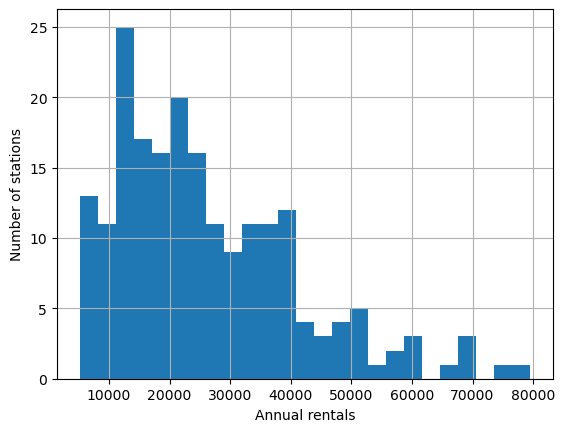

In [4]:
bike["annual_rentals"].hist(bins=25)
plt.xlabel("Annual rentals")
plt.ylabel("Number of stations")
plt.show()

### 2. 평일과 주말의 이용 시간 비교

`wd_h00`~`wd_h23`과 `we_h00`~`we_h23`을 각각 평균 내면, **한 대여소의 평균적인 시간대별 이용 모습**을 볼 수 있습니다. 서울시 전체 이용량의 합계가 아니라는 점에 주의하세요.

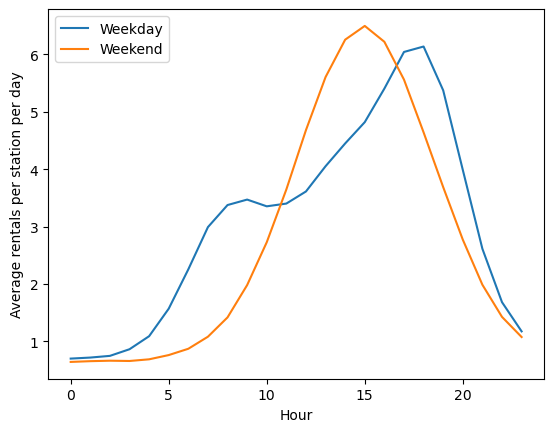

In [5]:
weekday = [f"wd_h{h:02}" for h in range(24)]
weekend = [f"we_h{h:02}" for h in range(24)]
hours = weekday + weekend

plt.plot(range(24), bike[weekday].mean(), label="Weekday")
plt.plot(range(24), bike[weekend].mean(), label="Weekend")
plt.xlabel("Hour")
plt.ylabel("Average rentals per station per day")
plt.legend()
plt.show()

### 3. 월별 변화 살펴보기

월별 총대여건수를 보면 계절에 따른 이용량 차이를 탐색할 수 있습니다. **월별 대여량만으로 출퇴근 목적이나 여가 목적을 단정할 수는 없습니다.**

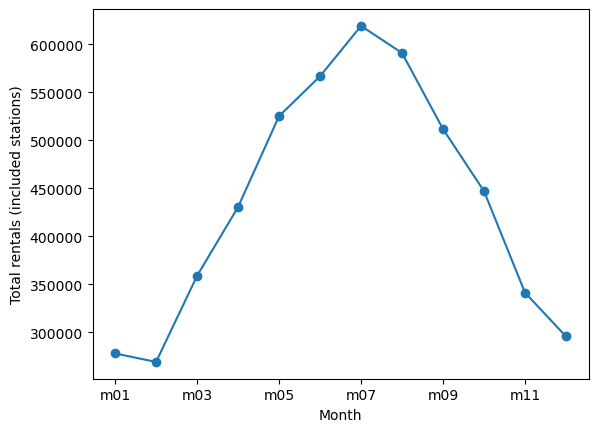

In [6]:
months = [f"m{m:02}" for m in range(1, 13)]
bike[months].sum().plot(marker="o")
plt.xlabel("Month")
plt.ylabel("Total rentals (included stations)")
plt.show()

**✍️ 프로젝트 기록 ①**

- 한 개의 데이터 샘플은 무엇인가요?
- 평일과 주말에 나타나는 시간대별 차이를 그래프의 근거와 함께 설명하세요.
- 데이터에서 더 탐색해 보고 싶은 질문을 하나 적으세요.

**AI 활용:** 그래프를 AI에 보여 주고 본인의 해석에 대한 반례를 물어보세요. AI가 그래프에서 확인할 수 없는 사실까지 주장하지 않는지도 확인합니다.

## 2주차. 비슷한 대여소를 어떻게 묶을까?

### 4. K-means에 사용할 특성 만들기

시간대별 대여건수 **그대로** 군집화하면 이용량이 많은 대여소끼리 묶일 수 있습니다. 이번 프로젝트에서는 시간대별 **이용 패턴**이 비슷한 대여소를 찾으려고 합니다.

그래서 대여소마다 48개 시간대 값의 합이 1이 되도록 나눕니다. 이렇게 만든 값은 **평일과 주말의 일평균을 같은 비중으로 합친 패턴 지표**이며, 실제 연간 대여 중 해당 시간대의 비중과는 다릅니다.

In [7]:
X_amount = bike[hours]                             # 대여건수 자체
X_pattern = X_amount.div(X_amount.sum(axis=1), axis=0)  # 시간대별 패턴
X = X_pattern                                     # TODO: X_amount와 비교해 보기
X.head()

,wd_h00,wd_h01,wd_h02,wd_h03,wd_h04,wd_h05,wd_h06,wd_h07,wd_h08,wd_h09,...,we_h14,we_h15,we_h16,we_h17,we_h18,we_h19,we_h20,we_h21,we_h22,we_h23
0,0.005378,0.005459,0.005928,0.007211,0.012365,0.020310,0.035242,0.047261,0.051457,0.046914,...,0.027402,0.026022,0.030009,0.025766,0.020449,0.017075,0.015797,0.012985,0.008947,0.007157
1,0.004863,0.004976,0.004415,0.006248,0.007669,0.012608,0.019529,0.027086,0.027610,0.026974,...,0.025726,0.029857,0.031547,0.026195,0.022158,0.019247,0.013614,0.008919,0.009107,0.007323
2,0.003289,0.003127,0.003966,0.003676,0.003063,0.002483,0.004707,0.004578,0.006932,0.013896,...,0.062061,0.058177,0.049924,0.051057,0.043289,0.032527,0.022656,0.018287,0.011166,0.009305
3,0.006261,0.006363,0.007040,0.007209,0.007108,0.009240,0.011034,0.013809,0.017024,0.017803,...,0.058353,0.061071,0.056569,0.051133,0.033721,0.034995,0.021829,0.015884,0.009938,0.008664
4,0.005283,0.005187,0.004993,0.007271,0.011536,0.020407,0.032137,0.045709,0.051575,0.044352,...,0.027857,0.026641,0.026884,0.029925,0.025789,0.018612,0.013989,0.010705,0.010340,0.009123


### 5. K-means 첫 실행

K-means는 **군집 수 `k`를 먼저 정한 후**, 대여소를 가까운 군집 중심(센트로이드)에 배정합니다. 군집 번호 0, 1, 2…에는 아직 의미가 없습니다.

In [8]:
model = KMeans(n_clusters=4, n_init=10, random_state=42)
labels = model.fit_predict(X)
pd.Series(labels).value_counts().sort_index()

c:\Users\gslee\miniforge3\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


0    50
1    50
2    50
3    50
Name: count, dtype: int64

### 6. 군집 수는 몇 개가 적절할까?

`k`를 2~7로 바꾸어 봅시다. **관성(Inertia)**은 군집 내부의 제곱 거리 합으로, 군집 수가 많아지면 대체로 작아집니다. **실루엣 점수**는 같은 군집끼리 얼마나 가깝고 서로 다른 군집끼리 얼마나 떨어져 있는지 보여 줍니다.

두 지표를 참고하되, **실제로 해석 가능한 유형인지**도 중요합니다.

In [9]:
results = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    group = km.fit_predict(X)
    score = silhouette_score(X, group, sample_size=500, random_state=42)
    results.append([k, km.inertia_, score])

scores = pd.DataFrame(results, columns=["k", "inertia", "silhouette"])
scores.round(3)

,k,inertia,silhouette
0,2,0.245,0.714
1,3,0.116,0.731
2,4,0.027,0.758
3,5,0.026,0.609
4,6,0.025,0.436
5,7,0.024,0.263


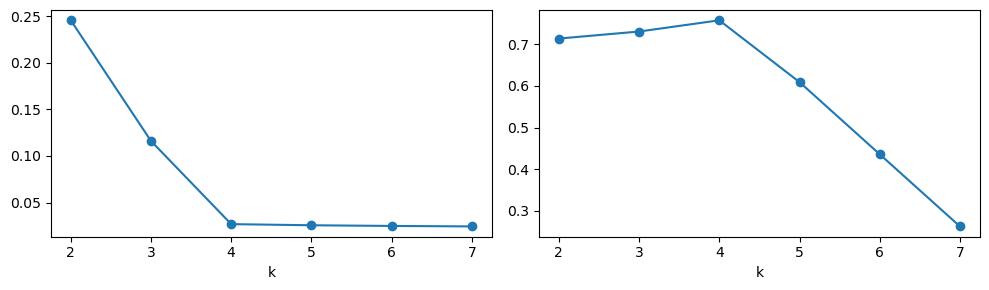

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
scores.plot(x="k", y="inertia", marker="o", ax=ax[0], legend=False)
scores.plot(x="k", y="silhouette", marker="o", ax=ax[1], legend=False)
plt.tight_layout()
plt.show()

### 7. 선택한 군집의 모습 확인

이제 `K` 값을 직접 정합니다. 첫 번째 그래프는 **평일**, 두 번째는 **주말**입니다. 군집마다 어느 시간에 상대적으로 많이 이용되는지 살펴보세요.

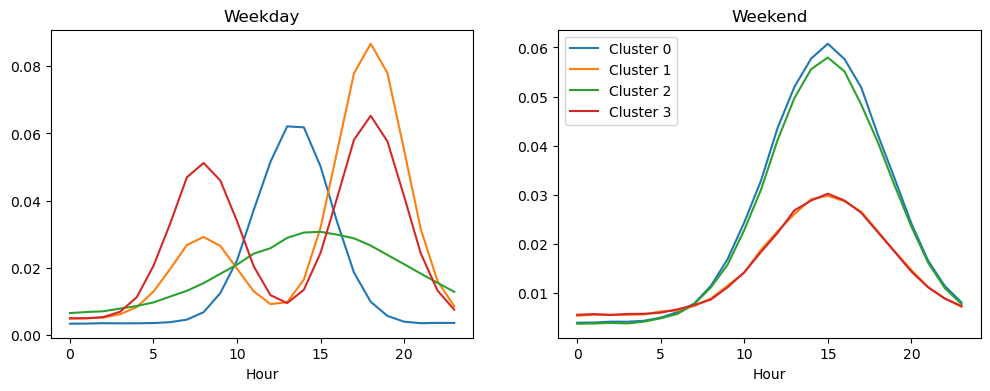

In [11]:
K = 4  # TODO: 점수와 그래프를 보고 직접 선택
model = KMeans(n_clusters=K, n_init=10, random_state=42)
bike["cluster"] = model.fit_predict(X)
pattern_by_cluster = X_pattern.groupby(bike["cluster"]).mean()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for cluster, values in pattern_by_cluster.iterrows():
    ax[0].plot(range(24), values[weekday], label=f"Cluster {cluster}")
    ax[1].plot(range(24), values[weekend], label=f"Cluster {cluster}")
ax[0].set(title="Weekday", xlabel="Hour")
ax[1].set(title="Weekend", xlabel="Hour")
ax[1].legend()
plt.show()

**✍️ 프로젝트 기록 ②**

- 왜 그 `K`를 선택했나요? 관성과 실루엣 점수, 그래프를 근거로 설명하세요.
- 군집별 평일·주말 패턴에서 가장 뚜렷한 차이는 무엇인가요?
- `X = X_amount`로 바꾸고 **4번부터 다시 실행**해 보세요. 군집이 달라진 이유는 무엇일까요? 이후 기본 분석을 계속하려면 `X = X_pattern`으로 되돌립니다.

## 3주차. 군집은 실제로 어떤 의미가 있을까?

### 8. 군집별 이용 규모 확인

패턴으로 묶었더라도 군집마다 대여량이 다를 수 있습니다. 대여소 수와 연간 이용량 중앙값을 확인합시다.

In [12]:
bike.groupby("cluster").agg(
    stations=("station_id", "size"),
    median_rentals=("annual_rentals", "median")
)

,stations,median_rentals
cluster,,
0,50,20734.0
1,50,21641.5
2,50,24936.5
3,50,22497.0


### 9. 군집별 월간 이용 패턴 확인

각 대여소의 월별 대여건수를 **그 대여소의 연간 대여건수**로 나눈 뒤 군집별로 평균을 냅니다. 대여소 규모의 차이를 줄이고 계절적 패턴을 비교하기 위해서입니다.

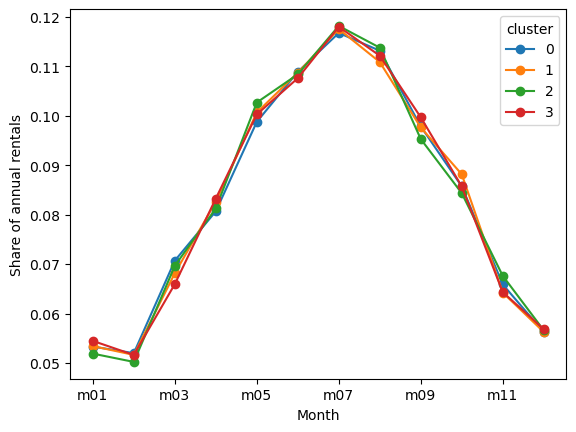

In [13]:
monthly_share = bike[months].div(bike["annual_rentals"], axis=0)
monthly_share.groupby(bike["cluster"]).mean().T.plot(marker="o")
plt.xlabel("Month")
plt.ylabel("Share of annual rentals")
plt.show()

### 10. 대여소 사례 확인

각 군집에 어떤 대여소가 속하는지 살펴봅니다. **아래는 군집별 앞의 세 곳을 보여 주는 예시일 뿐, 대표 대여소를 선정한 결과는 아닙니다.**

In [14]:
bike.groupby("cluster")[["station_name", "annual_rentals"]].head(3)

,station_name,annual_rentals
0,모의 대여소 001,38984
1,모의 대여소 002,21307
2,모의 대여소 003,20035
3,모의 대여소 004,19610
4,모의 대여소 005,16260
5,모의 대여소 006,14770
6,모의 대여소 007,31249
7,모의 대여소 008,44835
8,모의 대여소 009,8194
9,모의 대여소 010,18523


### 11. 분석 결과를 운영 제안으로 연결하기

군집의 이름을 **시간대별 그래프를 본 뒤 직접** 붙여 보세요. ‘출퇴근형’, ‘여가형’ 같은 명칭은 확인된 정답이 아니라 **해석 가설**입니다.

| 군집 | 평일·주말 패턴의 근거 | 월별 특징 | 임시 유형 이름 | 제안할 운영 방안 |
|---|---|---|---|---|
| 0 | | | | |
| 1 | | | | |
| 2 | | | | |
| 3 | | | | |

**✍️ 프로젝트 기록 ③ — 최종 판단**

1. 군집이 실제로 구분된다고 볼 만한 근거가 있나요? 점수와 그래프를 함께 제시하세요.
2. 가장 유용하다고 생각하는 군집 하나를 골라 운영 개선 아이디어를 제안하세요.
3. **이 자료만으로는 알 수 없는 것**을 두 가지 적으세요. 예: 반납량, 실제 자전거 부족, 주변 시설, 날씨의 영향.
4. AI가 제안한 설명 중 확인되지 않은 주장 한 가지를 찾아 수정하세요.

**주의:** 대여건수만으로 대여소의 이용 목적이나 자전거 재배치 필요성을 확정할 수 없습니다. 군집은 이용 패턴을 **요약하는 도구**이지 정책의 정답이 아닙니다.

---

### 최종 제출

**실행한 노트북 + 짧은 분석 보고서(1~2쪽)**

분석 질문 → 사용한 특성 → 군집 수 선택 근거 → 군집별 패턴 → 운영 제안과 한계 순서로 작성합니다. **코드 길이보다 분석의 근거와 해석의 정확성을 평가합니다.**

공식 원자료: [서울 열린데이터광장 — 공공자전거 이용정보(시간대별)](https://data.seoul.go.kr/dataList/OA-15245/F/1/datasetView.do)

> 이 노트북에 동봉된 `p5_demo_station_profiles_2025.csv`는 **모의 데이터**입니다. 실제 분석은 교수자가 제공하는 `p5_station_profiles_2025.csv`로 수행하세요.